# 8. Grad-CAM for model D (writer-ID features + per-writer SVM)

The forgery score of a questioned signature x for writer w is

    s(x) = -( sum_i a_i * exp(-gamma * ||sv_i - f(x)||^2) + b )

where f(x) is the L2-normalised CNN embedding and (sv_i, a_i, b, gamma) come from w's fitted SVM. That is
differentiable in f(x), so Grad-CAM can push ds/dA through the SVM into the last conv block A. The heatmap shows
the regions that make the signature look **unlike this writer's specimens**.

Each row: one test writer with a reference specimen, a genuine questioned signature and a skilled forgery.
Saves `runs/<ckpt>_fold<k>/gradcam_verifier.png`.

In [1]:
FOLD = 0
CKPT = "writerid"
N_REF = 5
ROWS = 5

In [2]:
%run ./common.ipynb

In [3]:
import matplotlib.pyplot as plt


class SVMGradCAM:
    def __init__(self, model, svm, device):
        self.model, self.acts, self.grads = model, None, None
        layer = model.features[-1]
        layer.register_forward_hook(lambda m, i, o: setattr(self, "acts", o))
        layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "grads", go[0]))
        self.sv = torch.tensor(svm.support_vectors_, dtype=torch.float32, device=device)
        self.a = torch.tensor(svm.dual_coef_[0], dtype=torch.float32, device=device)
        self.b, self.gamma = float(svm.intercept_[0]), float(svm._gamma)

    def score(self, x):
        f = torch.flatten(self.model.avgpool(self.model.features(x)), 1)
        f = f / f.norm(dim=1, keepdim=True)
        k = torch.exp(-self.gamma * ((self.sv - f) ** 2).sum(1))
        return -((self.a * k).sum() + self.b)

    def __call__(self, x):
        self.model.zero_grad(set_to_none=True)
        s = self.score(x)
        s.backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * self.acts).sum(1)).squeeze(0).detach().cpu().numpy()
        cam = cv2.resize(cam, (x.shape[3], x.shape[2]), interpolation=cv2.INTER_CUBIC)
        cam = np.clip(cam, 0, None)
        return cam / (cam.max() + 1e-8), s.item()

In [4]:
meta, tr, va, te = writer_split(fold=FOLD)
G = load_gray("binary")
F = cnn_features(CKPT, "binary", FOLD)
neg = F[tr[meta.label.values[tr] == 0]]
yv, sv, _ = score_writers(F, meta, sorted(set(meta.writer[va])), neg, N_REF)
thr, _ = eer_threshold(yv, sv)

model = build_model(pretrained=False).to(DEVICE).eval()
ck = torch.load(os.path.join(RUNS, f"{CKPT}_fold{FOLD}", "best.pt"), map_location=DEVICE)
model.features.load_state_dict(ck["features"])

# sanity check: the torch re-implementation of the SVM score matches scikit-learn on the same embedding
w0 = sorted(set(meta.writer[te]))[0]
svm0, quest0 = fit_writer_svm(F, meta, w0, neg, N_REF)
check = SVMGradCAM(model, svm0, DEVICE)
with torch.no_grad():
    f0 = torch.flatten(model.avgpool(model.features(torch.from_numpy(to_input(np.asarray(G[quest0[0]])))[None].to(DEVICE))), 1)
    f0 = f0 / f0.norm(dim=1, keepdim=True)
    k0 = torch.exp(-check.gamma * ((check.sv - f0) ** 2).sum(1))
    s_torch = -((check.a * k0).sum() + check.b).item()
print(f"SVM score check: torch {s_torch:.5f}  vs  sklearn {-svm0.decision_function(f0.cpu().numpy())[0]:.5f}")

SVM score check: torch 0.47040  vs  sklearn 0.47040


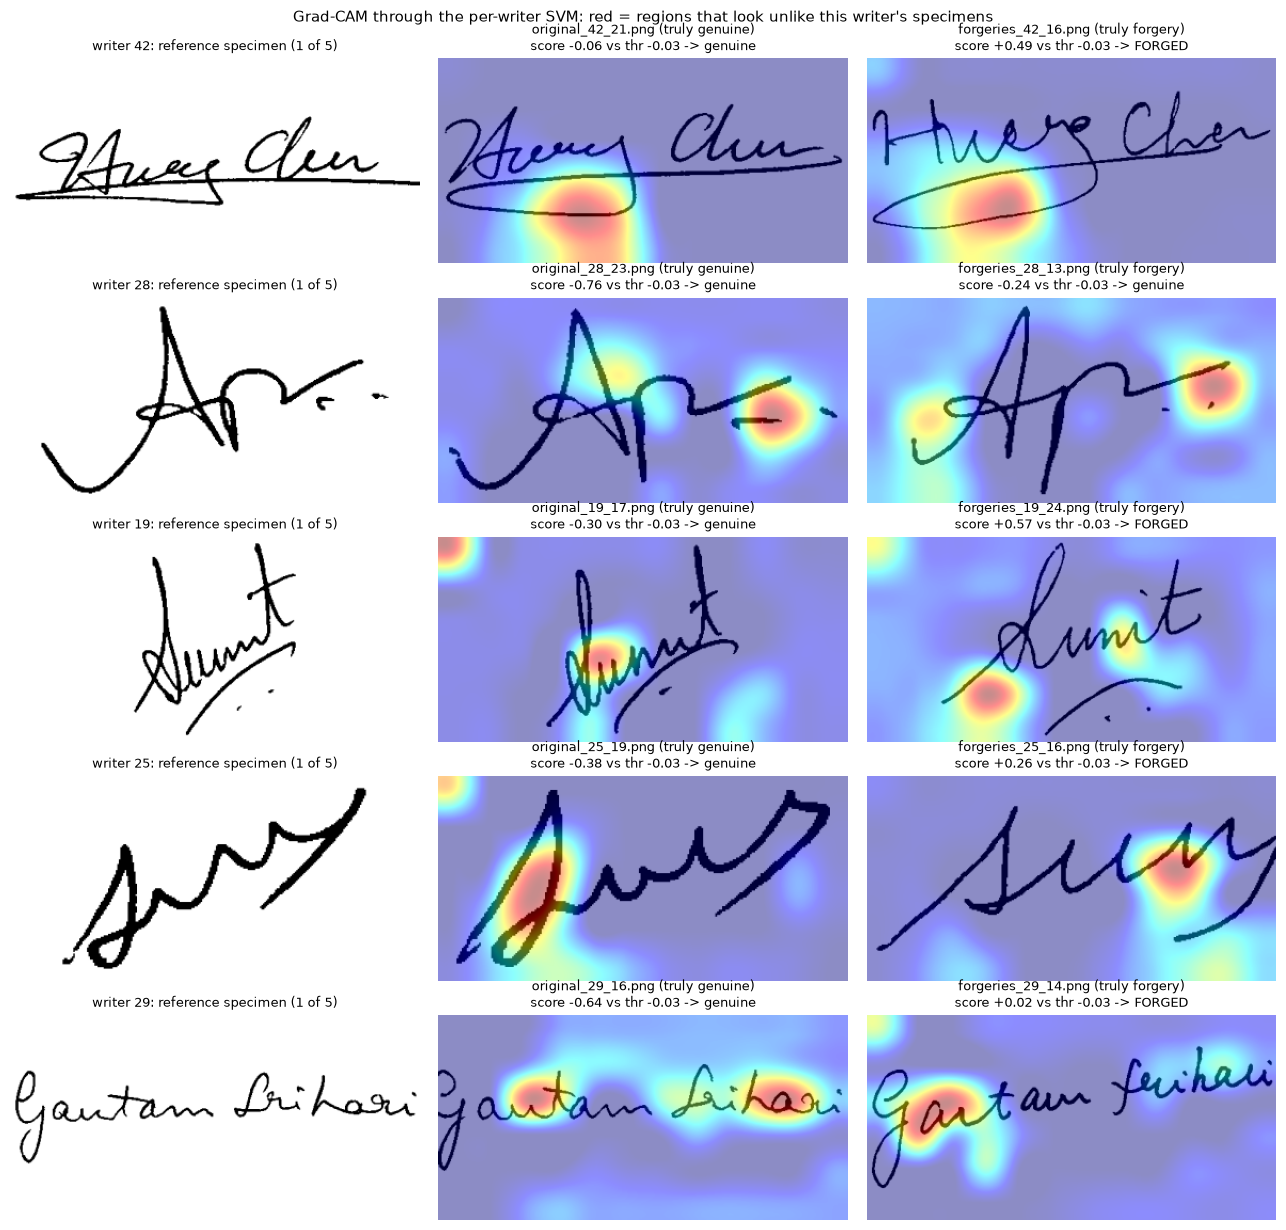

In [5]:
rng = np.random.default_rng(0)
writers = rng.choice(sorted(set(meta.writer[te])), ROWS, replace=False)
fig, axes = plt.subplots(ROWS, 3, figsize=(13, 2.5 * ROWS), squeeze=False)
for r, w in enumerate(writers):
    svm, quest = fit_writer_svm(F, meta, w, neg, N_REF)
    cam = SVMGradCAM(model, svm, DEVICE)
    ref = meta[(meta.writer == w) & (meta.label == 0) & (meta["index"] == 1)].index[0]
    gen = rng.choice([q for q in quest if meta.label[q] == 0])
    forg = rng.choice([q for q in quest if meta.label[q] == 1])
    axes[r, 0].imshow(np.asarray(G[ref]), cmap="gray")
    axes[r, 0].set_title(f"writer {w}: reference specimen (1 of {N_REF})", fontsize=9)
    for c, k in ((1, gen), (2, forg)):
        x = torch.from_numpy(to_input(np.asarray(G[k])))[None].to(DEVICE)
        heat, s = cam(x)
        verdict = "FORGED" if s >= thr else "genuine"
        truth = "forgery" if meta.label[k] else "genuine"
        axes[r, c].imshow(overlay(np.asarray(G[k]), heat))
        axes[r, c].set_title(f"{os.path.basename(meta.path[k])} (truly {truth})\n"
                             f"score {s:+.2f} vs thr {thr:+.2f} -> {verdict}", fontsize=9)
    for c in range(3):
        axes[r, c].axis("off")
plt.suptitle("Grad-CAM through the per-writer SVM: red = regions that look unlike this writer's specimens",
             fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(RUNS, f"{CKPT}_fold{FOLD}", "gradcam_verifier.png"), dpi=110, bbox_inches="tight")
plt.show()